# 1% Noise

# Plot

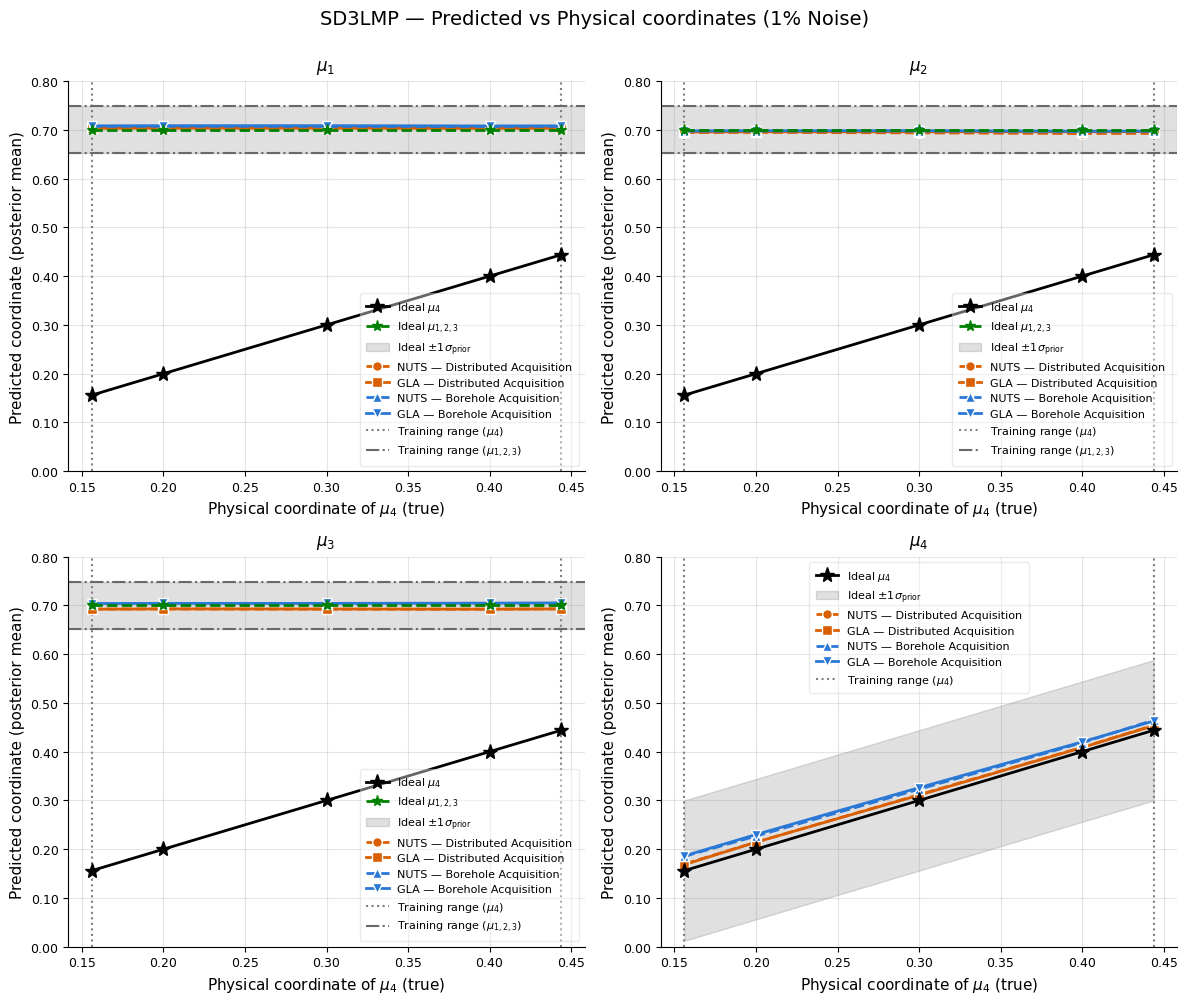

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Data ────────────────────────────────────────────────────────────────────
Physical_coordinates_mu_4 = np.array([0.15600001, 0.2, 0.3, 0.4, 0.44399999])   # x-axis (swept)
Physical_coordinates_mu_1 = np.array([0.7, 0.7, 0.7, 0.7, 0.7])   # y-axis (fixed)

# True/fixed values for mu_1, mu_2, mu_3 (not swept in this experiment)
true_mu_1 = 0.7
true_mu_2 = 0.7   # ASSUMPTION — update if mu_2's true fixed value differs
true_mu_3 = 0.7   # ASSUMPTION — update if mu_3's true fixed value differs

# Training-domain bounds
mu4_train_lo, mu4_train_hi = 0.15600001, 0.44399999   # vertical lines (mu_4 panel)
mu123_train_lo, mu123_train_hi = 0.652, 0.74800001    # horizontal lines (mu_1/2/3 panels)



data = {
    "mu_1": {
        "true": true_mu_1,
        "det_U": np.array( [0.70318096, 0.70366698, 0.70348763, 0.70312918, 0.70339001]),
        "nuts_U": np.array([0.70220369, 0.70216757, 0.70175433, 0.70230193, 0.70329328]),
        "det_N": np.array( [0.70825737, 0.70858334, 0.70866431, 0.70811914, 0.70827696]),
        "nuts_N": np.array([0.70716828, 0.70728986, 0.70697371, 0.70683964, 0.70706326]),
    },
    "mu_2": {
        "true": true_mu_2,
        "det_U": np.array( [0.69576442, 0.69609349, 0.69608622, 0.69605208, 0.69659065]),
        "nuts_U": np.array([0.69446825, 0.69482617, 0.69383434, 0.69250938, 0.69291062]),
        "det_N": np.array( [0.69795348, 0.69832207, 0.69846331, 0.69733861, 0.69763609]),
        "nuts_N": np.array([0.6975163 , 0.69773404, 0.6975497 , 0.69669136, 0.69740329]),
    },
    "mu_3": {
        "true": true_mu_3,
        "det_U": np.array( [0.6921358 , 0.69274551, 0.69254881, 0.69217445, 0.69263897]),
        "nuts_U": np.array([0.69245118, 0.69267244, 0.69228041, 0.69225929, 0.6929049 ]),
        "det_N": np.array( [0.70376831, 0.70411831, 0.70409088, 0.70459417, 0.70511571]),
        "nuts_N": np.array([0.70276794, 0.70286793, 0.70262222, 0.70277944, 0.70349811]),
    },
    "mu_4": {
        "true": None,   # identity line — true value equals x-axis itself
        "det_U": np.array( [0.16823882, 0.21434742, 0.31081573, 0.40840348, 0.45331161]),
        "nuts_U": np.array([0.16951941, 0.21436142, 0.3116489 , 0.40876349, 0.45421002]),
        "det_N": np.array( [0.18620118, 0.23007337, 0.32607697, 0.41999884, 0.462968  ]),
        "nuts_N": np.array([0.18523126, 0.22689081, 0.32288398, 0.41845816, 0.46477234]),
    },
}

# ── Style ─────────────────────────────────────────────────────────────────────
color_nonuniform = "#2a78d6"
color_uniform    = "#d95f02"
lw, ms = 2.0, 7

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

sigma_prior_1 = 0.048
sigma_prior_4 = 0.144
param_labels = {
    "mu_1": r"$\mu_1$ ",
    "mu_2": r"$\mu_2$ ",
    "mu_3": r"$\mu_3$ ",
    "mu_4": r"$\mu_4$ ",
}

for ax, (key, d) in zip(axes, data.items()):
        
        
    # Ideal / reference line
    if d["true"] is None:
        # mu_4: identity line y = x
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_4,
                 color="black", lw=lw, ls="-",
                 marker="*", markersize=ms + 4,
                 label=r"Ideal $\mu_{4}$", zorder=5)
        # mu_4 panel:
        ax.fill_between(Physical_coordinates_mu_4,
                        Physical_coordinates_mu_4 - sigma_prior_4,
                        Physical_coordinates_mu_4 + sigma_prior_4,
                        color="black", alpha=0.12, zorder=0,
                        label=r"Ideal $\pm 1\sigma_{\rm prior}$")
        
    elif d["true"] ==true_mu_1:
        # mu_1: identity line y = x
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_4,
                 color="black", lw=lw, ls="-",
                 marker="*", markersize=ms + 4,
                 label=r"Ideal $\mu_{4}$", zorder=5)
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_1,
                         color="green", lw=lw, ls="--",
                         marker="*", markersize=ms + 1,
                         label=r"Ideal $\mu_{1,2,3}$", zorder=5)
        # mu_1/mu_2/mu_3 panels:
        ax.axhspan(d["true"] - sigma_prior_1, d["true"] + sigma_prior_1,
                    color="black", alpha=0.12, zorder=0,
                    label=r"Ideal $\pm 1\sigma_{\rm prior}$")
            
    else:
        # mu_1/mu_2/mu_3: horizontal line at the true fixed value
        ax.axhline(y=d["true"], color="black", lw=lw, ls="-", zorder=5,
                    label="Ideal (true value)")

    # Uniform — NUTS (dashed, circle)
    ax.plot(Physical_coordinates_mu_4, d["nuts_U"],
            color=color_uniform, lw=lw, ls="--",
            marker="o", markersize=ms,
            markerfacecolor=color_uniform, markeredgecolor="white", markeredgewidth=1.0,
            label="NUTS — Distributed Acquisition")

    # Uniform — Deterministic (solid, square)
    ax.plot(Physical_coordinates_mu_4, d["det_U"],
            color=color_uniform, lw=lw, ls="-",
            marker="s", markersize=ms,
            markerfacecolor=color_uniform, markeredgecolor="white", markeredgewidth=1.0,
            label="GLA — Distributed Acquisition")

    # Non-uniform — NUTS (dashed, triangle up)
    ax.plot(Physical_coordinates_mu_4, d["nuts_N"],
            color=color_nonuniform, lw=lw, ls="--",
            marker="^", markersize=ms,
            markerfacecolor=color_nonuniform, markeredgecolor="white", markeredgewidth=1.0,
            label="NUTS — Borehole Acquisition")

    # Non-uniform — Deterministic (solid, triangle down)
    ax.plot(Physical_coordinates_mu_4, d["det_N"],
            color=color_nonuniform, lw=lw, ls="-",
            marker="v", markersize=ms,
            markerfacecolor=color_nonuniform, markeredgecolor="white", markeredgewidth=1.0,
            label="GLA — Borehole Acquisition")

    # ── Training-domain reference lines ────────────────────────────────────
    # Vertical lines: training range of mu_4 — shown in all panels, since the
    # x-axis (physical coordinate of mu_4) is shared across all four subplots.
    ax.axvline(x=mu4_train_lo, color="gray", lw=1.5, ls=":", zorder=1,
                label="Training range ($\\mu_4$)")
    ax.axvline(x=mu4_train_hi, color="gray", lw=1.5, ls=":", zorder=1)

    if key != "mu_4":
        # Horizontal lines: training range of mu_1/mu_2/mu_3 (y-axis is predicted value)
        ax.axhline(y=mu123_train_lo, color="dimgray", lw=1.5, ls="-.", zorder=1,
                    label="Training range ($\\mu_{1,2,3}$)")
        ax.axhline(y=mu123_train_hi, color="dimgray", lw=1.5, ls="-.", zorder=1)

    # ── Formatting per subplot ──────────────────────────────────────────────
    ax.set_xlabel(r"Physical coordinate of $\mu_4$ (true)", fontsize=11)
    ax.set_ylabel("Predicted coordinate (posterior mean)", fontsize=11)
    ax.set_title(param_labels[key], fontsize=12, pad=8)

    ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.tick_params(labelsize=9)
    
    ax.set_ylim(0, 0.8)
    ax.grid(color="gray", alpha=0.2, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, framealpha=0.4, loc="best", borderpad=0.6)
    
    

fig.suptitle("SD3LMP — Predicted vs Physical coordinates (1% Noise)",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig("SD3LMP_Inversion_1.pdf", bbox_inches="tight", dpi=150)
plt.savefig("SD3LMP_Inversion_1.png", bbox_inches="tight", dpi=150)
plt.show()


# Non - uniform
# shift = np.array([0,0,0,0.06]) # 0.45

(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype, device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 6583.930791232207.
Condition number: 6583.930791232207.
Condition number: 6583.930791232207.
Condition number: 6583.930791232207.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.012286247285415308
trace of M_obs: 437.939206084259
||del u||: 0.017502491025054898
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8982, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:445: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.444     ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:446: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.58799999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29999999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.9643)
 magnitude  tensor(10.8228)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9978)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9974)
Function error between true and surrogate using obs 
 tensor(0.0282)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9298)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9477)
U shape: torch.Size([400, 400])
S: tensor([11.0236,  7.0658,  4.8698,  2.5926])
S_true tensor([11.4222,  7.1758,  4.9800,  2.6234])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 2.6110e-06, -9.7871e-07,  9.3024e-07,  1.3936e-06],
        [-9.7871e-07,  1.5811e-06, -1.1269e-06, -4.4896e-07],
        [ 9.3024e-07, -1.1269e-06,  3.3324e-06,  1.8354e-06],
        [ 1.3936e-06, -4.4896e-07,  1.8354e-06,  1.4256e-05]])
Eigen values of Covariance of posterior
tensor([1.4791e-05+0.j, 4.1746e-06+0.j, 1.9930e-06+0.j, 8.2122e-07+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0233], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0868,  0.0823,  0.0855, -0.0154], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0016, 0.0013, 0.0018, 0.0038])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:523: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70827696]
 [0.5        0.         0.69763609]
 [0.9        0.         0.70511571]
 [0.1        0.         0.3       ]
 [0.5        0.         0.462968  ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:524: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.71215503]
 [0.5        0.         0.70065391]
 [0.9        0.         0.70949687]
 [0.1        0.         0.3       ]
 [0.5        0.         0.47202962]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:525: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.7043989 ]
 [0.5        0.         0.69461826]
 [0.9        0.         0.70073456]
 [0.1        0.         0.3       ]
 [0.5        0.         0.45390637]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:32, 31.22it/s, step size=1.97e-01, acc. prob=0.877]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:32, 31.22it/s, step size=1.94e-01, acc. prob=0.888]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:32, 31.22it/s, step size=2.12e-01, acc. prob=0.865]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:32, 31.22it/s, step size=1.89e-01, acc. prob=0.898]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.52it/s, step size=1.91e-01, acc. prob=0.897]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.09      0.00      0.09      0.08      0.09   2256.99      1.00
      mu_2      0.08      0.00      0.08      0.08      0.08   1761.20      1.00
      mu_3      0.08      0.00      0.08      0.08      0.09   1699.72      1.00
      mu_4     -0.01      0.00     -0.01     -0.02     -0.01    784.17      1.00

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0863) Posterior std:  tensor(0.0014)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0823) Posterior std:  tensor(0.0015)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0848) Posterior std:  tensor(0.0016)
Prior mean:  tensor(-0.0233) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0147) Posterior std:  tensor(0.0045)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70706326]
 [0.5        0.         0.69740329]
 [0.9        0.         0.70349811]
 [0.1        0.         0.3       ]
 [0.5        0.         0.46477234]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.71031625]
 [0.5        0.         0.70096465]
 [0.9        0.         0.70742807]
 [0.1        0.         0.3       ]
 [0.5        0.         0.47564596]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70381028]
 [0.5        0.         0.69384193]
 [0.9        0.         0.69956814]
 [0.1        0.         0.3       ]
 [0.5        0.         0.45389871]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:02:31.832406


,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0863),tensor(0.0014),tensor(0.0863),tensor(0.0840),tensor(0.0885),tensor(2256.9939),tensor(1.0005)
mu_2,tensor(0.0823),tensor(0.0015),tensor(0.0824),tensor(0.0799),tensor(0.0846),tensor(1761.1973),tensor(0.9996)
mu_3,tensor(0.0848),tensor(0.0016),tensor(0.0849),tensor(0.0820),tensor(0.0873),tensor(1699.7163),tensor(0.9998)
mu_4,tensor(-0.0147),tensor(0.0045),tensor(-0.0149),tensor(-0.0220),tensor(-0.0074),tensor(784.1681),tensor(1.0007)


# shift = np.array([0,0,0,0.08333333 * 0.5]) #0.4

(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype, device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 5895.935210802456.
Condition number: 5895.935210802456.
Condition number: 5895.935210802456.
Condition number: 5895.935210802456.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.012390373987244192
trace of M_obs: 437.939206084259
||del u||: 0.017429086822043107
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8886, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:445: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.39999999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:446: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.54399998]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.25599998]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.9643)
 magnitude  tensor(10.8678)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9978)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9974)
Function error between true and surrogate using obs 
 tensor(0.0282)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9616)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9686)
U shape: torch.Size([400, 400])
S: tensor([10.3072,  6.9998,  4.9904,  2.6041])
S_true tensor([10.2345,  6.9753,  5.0007,  2.6114])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 2.5846e-06, -9.5672e-07,  8.0179e-07,  1.4471e-06],
        [-9.5672e-07,  1.7411e-06, -1.0823e-06, -5.4850e-07],
        [ 8.0179e-07, -1.0823e-06,  3.1441e-06,  1.7381e-06],
        [ 1.4471e-06, -5.4850e-07,  1.7381e-06,  1.4139e-05]])
Eigen values of Covariance of posterior
tensor([1.4662e-05+0.j, 3.9771e-06+0.j, 2.0306e-06+0.j, 9.3908e-07+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0417], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0867,  0.0822,  0.0852, -0.0333], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0016, 0.0013, 0.0018, 0.0038])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:523: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70811914]
 [0.5        0.         0.69733861]
 [0.9        0.         0.70459417]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41999884]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:524: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.71197759]
 [0.5        0.         0.70050541]
 [0.9        0.         0.70884974]
 [0.1        0.         0.3       ]
 [0.5        0.         0.42902337]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:525: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70426069]
 [0.5        0.         0.69417182]
 [0.9        0.         0.70033859]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41097432]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy

############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.87it/s, step size=2.12e-01, acc. prob=0.863]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.87it/s, step size=1.97e-01, acc. prob=0.888]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.87it/s, step size=2.26e-01, acc. prob=0.859]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.87it/s, step size=2.01e-01, acc. prob=0.887]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.87it/s, step size=2.25e-01, acc. prob=0.858]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: to get more information on the crash.
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.09      0.00      0.09      0.08      0.09   2202.31      1.00
      mu_2      0.08      0.00      0.08      0.08      0.08   1834.38      1.00
      mu_3      0.08      0.00      0.08      0.08      0.09   1568.07      1.00
      mu_4     -0.03      0.00     -0.03     -0.04     -0.03   1068.79      1.00

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0862) Posterior std:  tensor(0.0014)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0820) Posterior std:  tensor(0.0016)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0845) Posterior std:  tensor(0.0016)
Prior mean:  tensor(-0.0417) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0340) Posterior std:  tensor(0.0037)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70683964]
 [0.5        0.         0.69669136]
 [0.9        0.         0.70277944]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41845816]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.71020486]
 [0.5        0.         0.70050258]
 [0.9        0.         0.70670367]
 [0.1        0.         0.3       ]
 [0.5        0.         0.42730061]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70347441]
 [0.5        0.         0.69288014]
 [0.9        0.         0.69885521]
 [0.1        0.         0.3       ]
 [0.5        0.         0.40961572]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:02:24.078782


,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0862),tensor(0.0014),tensor(0.0862),tensor(0.0837),tensor(0.0883),tensor(2202.3140),tensor(1.0002)
mu_2,tensor(0.0820),tensor(0.0016),tensor(0.0821),tensor(0.0795),tensor(0.0846),tensor(1834.3798),tensor(1.0022)
mu_3,tensor(0.0845),tensor(0.0016),tensor(0.0846),tensor(0.0818),tensor(0.0871),tensor(1568.0663),tensor(1.0003)
mu_4,tensor(-0.0340),tensor(0.0037),tensor(-0.0340),tensor(-0.0402),tensor(-0.0281),tensor(1068.7926),tensor(0.9991)


# shift = np.array([0,0,0,0]) #0.3

(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype, device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 4381.140517965101.
Condition number: 4381.140517965101.
Condition number: 4381.140517965101.
Condition number: 4381.140517965101.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.012607583677544462
trace of M_obs: 437.939206084259
||del u||: 0.01727946299190609
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8715, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:445: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29999999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:446: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.44399999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15600001]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.9643)
 magnitude  tensor(10.9599)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9979)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9975)
Function error between true and surrogate using obs 
 tensor(0.0270)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9501)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9612)
U shape: torch.Size([400, 400])
S: tensor([8.8945, 6.9391, 5.0529, 2.1460])
S_true tensor([8.6901, 6.8918, 5.0556, 1.8809])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 2.6207e-06, -8.7339e-07,  6.2993e-07,  2.1234e-06],
        [-8.7339e-07,  2.2886e-06, -9.4132e-07,  6.3094e-08],
        [ 6.2993e-07, -9.4132e-07,  2.7809e-06,  2.0754e-06],
        [ 2.1234e-06,  6.3094e-08,  2.0754e-06,  2.1071e-05]])
Eigen values of Covariance of posterior
tensor([2.1556e-05+0.j, 3.8793e-06+0.j, 1.2601e-06+0.j, 2.0660e-06+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0833], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0869,  0.0827,  0.0850, -0.0725], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0016, 0.0015, 0.0017, 0.0046])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:523: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70866431]
 [0.5        0.         0.69846331]
 [0.9        0.         0.70409088]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32607697]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:524: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.71254956]
 [0.5        0.         0.70209404]
 [0.9        0.         0.70809314]
 [0.1        0.         0.3       ]
 [0.5        0.         0.33709385]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:525: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70477906]
 [0.5        0.         0.69483259]
 [0.9        0.         0.70008861]
 [0.1        0.         0.3       ]
 [0.5        0.         0.31506008]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy

############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.97it/s, step size=2.26e-01, acc. prob=0.866]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.97it/s, step size=2.31e-01, acc. prob=0.851]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.97it/s, step size=2.18e-01, acc. prob=0.878]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.97it/s, step size=2.58e-01, acc. prob=0.812]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.97it/s, step size=1.91e-01, acc. prob=0.905]                                                                                           





[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.09      0.00      0.09      0.08      0.09   2265.26      1.00
      mu_2      0.08      0.00      0.08      0.08      0.09   1897.78      1.00
      mu_3      0.08      0.00      0.08      0.08      0.09   2033.80      1.00
      mu_4     -0.07      0.00     -0.07     -0.08     -0.07    877.03      1.01

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0862) Posterior std:  tensor(0.0014)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0823) Posterior std:  tensor(0.0016)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0844) Posterior std:  tensor(0.0016)
Prior mean:  tensor(-0.0833) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0738) Posterior std:  tensor(0.0043)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70697371]
 [0.5        0.         0.6975497 ]
 [0.9        0.         0.70262222]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32288398]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.71037871]
 [0.5        0.         0.70147017]
 [0.9        0.         0.7064334 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.33309188]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70356872]
 [0.5        0.         0.69362923]
 [0.9        0.         0.69881104]
 [0.1        0.         0.3       ]
 [0.5        0.         0.31267607]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:02:20.123956
 

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0862),tensor(0.0014),tensor(0.0863),tensor(0.0839),tensor(0.0885),tensor(2265.2620),tensor(1.0002)
mu_2,tensor(0.0823),tensor(0.0016),tensor(0.0825),tensor(0.0798),tensor(0.0851),tensor(1897.7794),tensor(1.0005)
mu_3,tensor(0.0844),tensor(0.0016),tensor(0.0845),tensor(0.0818),tensor(0.0870),tensor(2033.8027),tensor(0.9995)
mu_4,tensor(-0.0738),tensor(0.0043),tensor(-0.0736),tensor(-0.0812),tensor(-0.0671),tensor(877.0276),tensor(1.0051)



# shift = np.array([0,0,0,-0.08333333 * 0.5]) #0.2

(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype, device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 3252.9102788407536.
Condition number: 3252.9102788407536.
Condition number: 3252.9102788407536.
Condition number: 3252.9102788407536.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.012818663109266519
trace of M_obs: 437.939206084259
||del u||: 0.017137932090423524
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8548, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:445: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.2       ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:446: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.34400001]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.05599999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.9643)
 magnitude  tensor(11.0517)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9978)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9975)
Function error between true and surrogate using obs 
 tensor(0.0277)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9557)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9638)
U shape: torch.Size([400, 400])
S: tensor([8.6880, 6.9717, 5.0539, 2.0925])
S_true tensor([8.4446, 6.9359, 4.9930, 2.0406])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 2.5916e-06, -8.5797e-07,  6.2711e-07,  2.3484e-06],
        [-8.5797e-07,  2.4915e-06, -9.2016e-07,  1.9599e-07],
        [ 6.2711e-07, -9.2016e-07,  2.7640e-06,  2.4765e-06],
        [ 2.3484e-06,  1.9599e-07,  2.4765e-06,  2.2057e-05]])
Eigen values of Covariance of posterior
tensor([2.2659e-05+0.j, 3.8777e-06+0.j, 1.3205e-06+0.j, 2.0469e-06+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.1250], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0869,  0.0826,  0.0850, -0.1125], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0016, 0.0016, 0.0017, 0.0047])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:523: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70858334]
 [0.5        0.         0.69832207]
 [0.9        0.         0.70411831]
 [0.1        0.         0.3       ]
 [0.5        0.         0.23007337]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:524: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.71244699]
 [0.5        0.         0.70211035]
 [0.9        0.         0.70810838]
 [0.1        0.         0.3       ]
 [0.5        0.         0.24134489]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:525: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70471969]
 [0.5        0.         0.69453379]
 [0.9        0.         0.70012823]
 [0.1        0.         0.3       ]
 [0.5        0.         0.21880186]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy

############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:31, 32.19it/s, step size=2.36e-01, acc. prob=0.874]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:31, 32.19it/s, step size=2.45e-01, acc. prob=0.851]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:31, 32.19it/s, step size=2.19e-01, acc. prob=0.883]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:31, 32.19it/s, step size=2.00e-01, acc. prob=0.911]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:31, 32.19it/s, step size=2.33e-01, acc. prob=0.879]                                                                                           





[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.09      0.00      0.09      0.08      0.09   1857.98      1.00
      mu_2      0.08      0.00      0.08      0.08      0.09   2021.01      1.00
      mu_3      0.08      0.00      0.08      0.08      0.09   1994.71      1.00
      mu_4     -0.11      0.00     -0.11     -0.12     -0.11    806.69      1.01

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0864) Posterior std:  tensor(0.0014)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0824) Posterior std:  tensor(0.0017)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0845) Posterior std:  tensor(0.0016)
Prior mean:  tensor(-0.1250) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1138) Posterior std:  tensor(0.0043)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70728986]
 [0.5        0.         0.69773404]
 [0.9        0.         0.70286793]
 [0.1        0.         0.3       ]
 [0.5        0.         0.22689081]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.71072602]
 [0.5        0.         0.70175048]
 [0.9        0.         0.70659381]
 [0.1        0.         0.3       ]
 [0.5        0.         0.23719732]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70385369]
 [0.5        0.         0.6937176 ]
 [0.9        0.         0.69914205]
 [0.1        0.         0.3       ]
 [0.5        0.         0.2165843 ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:02:23.874369

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0864),tensor(0.0014),tensor(0.0864),tensor(0.0839),tensor(0.0885),tensor(1857.9774),tensor(1.0039)
mu_2,tensor(0.0824),tensor(0.0017),tensor(0.0825),tensor(0.0796),tensor(0.0852),tensor(2021.0074),tensor(1.0018)
mu_3,tensor(0.0845),tensor(0.0016),tensor(0.0846),tensor(0.0820),tensor(0.0871),tensor(1994.7078),tensor(1.0026)
mu_4,tensor(-0.1138),tensor(0.0043),tensor(-0.1136),tensor(-0.1209),tensor(-0.1069),tensor(806.6907),tensor(1.0089)



# shift = np.array([0,0,0,-0.06]) #0.15

(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype, device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 2959.4629062502563.
Condition number: 2959.4629062502563.
Condition number: 2959.4629062502563.
Condition number: 2959.4629062502563.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.012899777144779682
trace of M_obs: 437.939206084259
||del u||: 0.01708445457346632
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8539, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:445: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15600001]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:446: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.30000001]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.012]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.9643)
 magnitude  tensor(11.0853)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9978)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9975)
Function error between true and surrogate using obs 
 tensor(0.0276)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9496)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9649)
U shape: torch.Size([400, 400])
S: tensor([8.6194, 6.9380, 5.0406, 1.9551])
S_true tensor([8.4657, 6.9381, 4.9650, 1.9680])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 2.5588e-06, -8.6459e-07,  6.0841e-07,  2.5389e-06],
        [-8.6459e-07,  2.5433e-06, -9.4772e-07,  4.2333e-08],
        [ 6.0841e-07, -9.4772e-07,  2.8049e-06,  2.6697e-06],
        [ 2.5389e-06,  4.2333e-08,  2.6697e-06,  2.5333e-05]])
Eigen values of Covariance of posterior
tensor([2.5934e-05+0.j, 3.8980e-06+0.j, 1.3415e-06+0.j, 2.0667e-06+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.1433], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0868,  0.0825,  0.0849, -0.1307], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0016, 0.0016, 0.0017, 0.0050])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:523: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70825737]
 [0.5        0.         0.69795348]
 [0.9        0.         0.70376831]
 [0.1        0.         0.3       ]
 [0.5        0.         0.18620118]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:524: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.71209646]
 [0.5        0.         0.70178097]
 [0.9        0.         0.70778782]
 [0.1        0.         0.3       ]
 [0.5        0.         0.19828081]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:525: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70441827]
 [0.5        0.         0.69412599]
 [0.9        0.         0.69974881]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17412155]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:32, 30.59it/s, step size=2.31e-01, acc. prob=0.881]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:32, 30.59it/s, step size=2.14e-01, acc. prob=0.903]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:32, 30.59it/s, step size=2.28e-01, acc. prob=0.880]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:32, 30.59it/s, step size=2.20e-01, acc. prob=0.888]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:32, 30.59it/s, step size=2.36e-01, acc. prob=0.875]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
------------------------------------------------------------------------
[0]PETSC ERROR: [0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: [0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: [0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: [0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: [0]PETSC ERROR: to get more information on the crash.
to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.09      0.00      0.09      0.08      0.09   1965.37      1.00
      mu_2      0.08      0.00      0.08      0.08      0.09   1944.48      1.00
      mu_3      0.08      0.00      0.08      0.08      0.09   1857.83      1.00
      mu_4     -0.13      0.00     -0.13     -0.14     -0.12    946.15      1.00

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0863) Posterior std:  tensor(0.0014)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0823) Posterior std:  tensor(0.0017)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0845) Posterior std:  tensor(0.0017)
Prior mean:  tensor(-0.1433) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1312) Posterior std:  tensor(0.0050)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70716828]
 [0.5        0.         0.6975163 ]
 [0.9        0.         0.70276794]
 [0.1        0.         0.3       ]
 [0.5        0.         0.18523126]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.7106383 ]
 [0.5        0.         0.70168521]
 [0.9        0.         0.70674803]
 [0.1        0.         0.3       ]
 [0.5        0.         0.19719835]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70369826]
 [0.5        0.         0.69334739]
 [0.9        0.         0.69878784]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17326417]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:02:35.720256


,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0863),tensor(0.0014),tensor(0.0863),tensor(0.0842),tensor(0.0888),tensor(1965.3734),tensor(0.9996)
mu_2,tensor(0.0823),tensor(0.0017),tensor(0.0824),tensor(0.0796),tensor(0.0853),tensor(1944.4807),tensor(1.0005)
mu_3,tensor(0.0845),tensor(0.0017),tensor(0.0846),tensor(0.0819),tensor(0.0873),tensor(1857.8344),tensor(1.0003)
mu_4,tensor(-0.1312),tensor(0.0050),tensor(-0.1311),tensor(-0.1388),tensor(-0.1226),tensor(946.1533),tensor(1.0040)


# Non - uniform
# shift = np.array([0,0,0,0.06]) # 0.7, 0.7, 0.7, 0.45
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652      , 0.70000001 , 0.74800001
0.652      , 0.70000001 , 0.74800001
0.29999999 , 0.444      , 0.58799999
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.0233   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0868    \pm     0.0016
              0.0823    \pm     0.0013
              0.0855    \pm     0.0018
              -0.0154   \pm     0.0038
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.7043989  , 0.70827696 , 0.71215503
0.69461826 , 0.69763609 , 0.70065391
0.70073456 , 0.70511571 , 0.70949687
0.45390637 , 0.462968   , 0.47202962

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0863),tensor(0.0014),tensor(0.0863),tensor(0.0840),tensor(0.0885),tensor(2256.9939),tensor(1.0005)
mu_2,tensor(0.0823),tensor(0.0015),tensor(0.0824),tensor(0.0799),tensor(0.0846),tensor(1761.1973),tensor(0.9996)
mu_3,tensor(0.0848),tensor(0.0016),tensor(0.0849),tensor(0.0820),tensor(0.0873),tensor(1699.7163),tensor(0.9998)
mu_4,tensor(-0.0147),tensor(0.0045),tensor(-0.0149),tensor(-0.0220),tensor(-0.0074),tensor(784.1681),tensor(1.0007)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.70381028 , 0.70706326 , 0.71031625
0.69384193 , 0.69740329 , 0.70096465
0.69956814 , 0.70349811 , 0.70742807
0.45389871 , 0.46477234 , 0.47564596

# shift = np.array([0,0,0,0.08333333 * 0.5]) # 0.7, 0.7, 0.7,0.4
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.25599998 , 0.39999999 , 0.54399998
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.0417   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0867    \pm     0.0016
              0.0822    \pm     0.0013
              0.0852    \pm     0.0018
              -0.0333   \pm     0.0038
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.7042606 , 0.70811914 , 0.71197759
0.69417182 , 0.69733861 , 0.70050541
0.70033859 , 0.70459417 , 0.70884974
0.41097432 , 0.41999884 , 0.42902337

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0862),tensor(0.0014),tensor(0.0862),tensor(0.0837),tensor(0.0883),tensor(2202.3140),tensor(1.0002)
mu_2,tensor(0.0820),tensor(0.0016),tensor(0.0821),tensor(0.0795),tensor(0.0846),tensor(1834.3798),tensor(1.0022)
mu_3,tensor(0.0845),tensor(0.0016),tensor(0.0846),tensor(0.0818),tensor(0.0871),tensor(1568.0663),tensor(1.0003)
mu_4,tensor(-0.0340),tensor(0.0037),tensor(-0.0340),tensor(-0.0402),tensor(-0.0281),tensor(1068.7926),tensor(0.9991)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.70347441 , 0.70683964 , 0.71020486
0.69288014 , 0.69669136 , 0.70050258
0.69885521 , 0.70277944 , 0.70670367
0.40961572 , 0.41845816 , 0.42730061

# shift = np.array([0,0,0,0]) # 0.7, 0.7, 0.7,0.3
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.15600001 , 0.29999999 , 0.44399999
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.0833   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0869    \pm     0.0016
              0.0827    \pm     0.0015
              0.0850    \pm     0.0017
              -0.0725   \pm     0.0046
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.70477906 , 0.70866431 , 0.71254956
0.69483259 , 0.69846331 , 0.70209404
0.70008861 , 0.70409088 , 0.70809314
0.31506008 , 0.32607697 , 0.33709385

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0862),tensor(0.0014),tensor(0.0863),tensor(0.0839),tensor(0.0885),tensor(2265.2620),tensor(1.0002)
mu_2,tensor(0.0823),tensor(0.0016),tensor(0.0825),tensor(0.0798),tensor(0.0851),tensor(1897.7794),tensor(1.0005)
mu_3,tensor(0.0844),tensor(0.0016),tensor(0.0845),tensor(0.0818),tensor(0.0870),tensor(2033.8027),tensor(0.9995)
mu_4,tensor(-0.0738),tensor(0.0043),tensor(-0.0736),tensor(-0.0812),tensor(-0.0671),tensor(877.0276),tensor(1.0051)


# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.70356872 , 0.70697371 , 0.71037871
0.69362923 , 0.6975497  , 0.70147017
0.69881104 , 0.70262222 , 0.7064334 
0.31267607 , 0.32288398 , 0.33309188

# shift = np.array([0,0,0,-0.08333333 * 0.5]) #0.7, 0.7, 0.7, 0.2
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.05599999 , 0.2        , 0.34400001
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.1250   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0869    \pm     0.0016
              0.0826    \pm     0.0016
              0.0850    \pm     0.0017
              -0.1125   \pm     0.0047
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.70471969 , 0.70858334 , 0.71244699
0.69453379 , 0.69832207 , 0.70211035
0.70012823 , 0.70411831 , 0.70810838
0.21880186 , 0.23007337 , 0.24134489

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0864),tensor(0.0014),tensor(0.0864),tensor(0.0839),tensor(0.0885),tensor(1857.9774),tensor(1.0039)
mu_2,tensor(0.0824),tensor(0.0017),tensor(0.0825),tensor(0.0796),tensor(0.0852),tensor(2021.0074),tensor(1.0018)
mu_3,tensor(0.0845),tensor(0.0016),tensor(0.0846),tensor(0.0820),tensor(0.0871),tensor(1994.7078),tensor(1.0026)
mu_4,tensor(-0.1138),tensor(0.0043),tensor(-0.1136),tensor(-0.1209),tensor(-0.1069),tensor(806.6907),tensor(1.0089)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.70385369 , 0.70728986 , 0.71072602
0.6937176  , 0.69773404 , 0.70175048
0.69914205 , 0.70286793 , 0.70659381
0.2165843  , 0.22689081 , 0.23719732

# shift = np.array([0,0,0,-0.06]) #0.7, 0.7, 0.7, 0.15
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.012      , 0.15600001 , 0.30000001
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.1433   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0868    \pm     0.0016
              0.0825    \pm     0.0016
              0.0849    \pm     0.0017
              -0.1307   \pm     0.0050
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.70441827 , 0.70825737 , 0.71209646
0.69412599 , 0.69795348 , 0.70178097
0.69974881 , 0.70376831 , 0.70778782
0.17412155 , 0.18620118 , 0.19828081

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0863),tensor(0.0014),tensor(0.0863),tensor(0.0842),tensor(0.0888),tensor(1965.3734),tensor(0.9996)
mu_2,tensor(0.0823),tensor(0.0017),tensor(0.0824),tensor(0.0796),tensor(0.0853),tensor(1944.4807),tensor(1.0005)
mu_3,tensor(0.0845),tensor(0.0017),tensor(0.0846),tensor(0.0819),tensor(0.0873),tensor(1857.8344),tensor(1.0003)
mu_4,tensor(-0.1312),tensor(0.0050),tensor(-0.1311),tensor(-0.1388),tensor(-0.1226),tensor(946.1533),tensor(1.0040)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.70369826 , 0.70716828 , 0.7106383 
0.69334739 , 0.6975163  , 0.70168521
0.69878784 , 0.70276794 , 0.70674803
0.17326417 , 0.18523126 , 0.19719835

# uniform
# shift = np.array([0,0,0,0.06]) # 0.45

(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creatinga tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype,device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 6583.930791232207.
Condition number: 6583.930791232207.
Condition number: 6583.930791232207.
Condition number: 6583.930791232207.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_norm: 82.62488408691279
u_M_norm.shape: 0.02555043296212888
trace of M_obs: 0.13051056908556816
||del u||: 0.02082266751405799
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8935, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.444     ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:448: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.58799999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:449: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29999999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(9.2038)
 magnitude  tensor(9.0962)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9978)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9976)
Function error between true and surrogate using obs 
 tensor(0.0222)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9298)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9306)
U shape: torch.Size([400, 400])
S: tensor([8.5780, 4.6925, 3.0476, 2.5081])
S_true tensor([8.9126, 4.7661, 3.1002, 2.4666])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 5.9168e-06, -2.4021e-06,  2.0875e-06,  9.6482e-07],
        [-2.4021e-06,  3.3893e-06, -2.7491e-06,  1.0036e-06],
        [ 2.0875e-06, -2.7491e-06,  7.4418e-06,  1.3681e-06],
        [ 9.6482e-07,  1.0036e-06,  1.3681e-06,  1.5388e-05]])
Eigen values of Covariance of posterior
tensor([1.3545e-06+0.j, 4.4905e-06+0.j, 1.0495e-05+0.j, 1.5796e-05+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0233], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0847,  0.0819,  0.0803, -0.0195], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0024, 0.0018, 0.0027, 0.0039])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:530: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70339001]
 [0.5        0.         0.69659065]
 [0.9        0.         0.69263897]
 [0.1        0.         0.3       ]
 [0.5        0.         0.45331161]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:531: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70922791]
 [0.5        0.         0.70100909]
 [0.9        0.         0.6991861 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.46272627]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.69755211]
 [0.5        0.         0.69217221]
 [0.9        0.         0.68609184]
 [0.1        0.         0.3       ]
 [0.5        0.         0.44389695]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:42, 23.31it/s, step size=3.11e-01, acc. prob=0.841]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:42, 23.31it/s, step size=2.98e-01, acc. prob=0.852]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:42, 23.31it/s, step size=3.09e-01, acc. prob=0.848]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:42, 23.31it/s, step size=3.11e-01, acc. prob=0.846]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:42, 23.31it/s, step size=2.58e-01, acc. prob=0.912]                                                                                           





[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.08      0.00      0.08      0.08      0.09   1802.89      1.00
      mu_2      0.08      0.00      0.08      0.08      0.08   1735.61      1.00
      mu_3      0.08      0.00      0.08      0.08      0.08   1935.78      1.00
      mu_4     -0.02      0.00     -0.02     -0.03     -0.01   1697.67      1.00

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0847) Posterior std:  tensor(0.0025)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0804) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0804) Posterior std:  tensor(0.0026)
Prior mean:  tensor(-0.0233) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0191) Posterior std:  tensor(0.0041)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70329328]
 [0.5        0.         0.69291062]
 [0.9        0.         0.6929049 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.45421002]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.7093714 ]
 [0.5        0.         0.69903134]
 [0.9        0.         0.69909418]
 [0.1        0.         0.3       ]
 [0.5        0.         0.46393683]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.69721515]
 [0.5        0.         0.68678991]
 [0.9        0.         0.68671563]
 [0.1        0.         0.3       ]
 [0.5        0.         0.4444832 ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:02:50.465449

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0847),tensor(0.0025),tensor(0.0848),tensor(0.0805),tensor(0.0886),tensor(1802.8866),tensor(0.9995)
mu_2,tensor(0.0804),tensor(0.0026),tensor(0.0806),tensor(0.0762),tensor(0.0845),tensor(1735.6122),tensor(1.0019)
mu_3,tensor(0.0804),tensor(0.0026),tensor(0.0804),tensor(0.0763),tensor(0.0847),tensor(1935.7781),tensor(0.9995)
mu_4,tensor(-0.0191),tensor(0.0041),tensor(-0.0192),tensor(-0.0261),tensor(-0.0129),tensor(1697.6678),tensor(1.0018)


# shift = np.array([0,0,0,0.08333333 * 0.5]) #0.4 
(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype, device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 5895.935210802456.
Condition number: 5895.935210802456.
Condition number: 5895.935210802456.
Condition number: 5895.935210802456.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_norm: 83.21146915265592
u_M_norm.shape: 0.02575249776398525
trace of M_obs: 0.13051056908556816
||del u||: 0.020749144791049858
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8748, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.39999999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:448: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.54399998]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:449: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.25599998]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(9.2038)
 magnitude  tensor(9.1281)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9978)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9975)
Function error between true and surrogate using obs 
 tensor(0.0224)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9616)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9644)
U shape: torch.Size([400, 400])
S: tensor([8.0614, 4.6329, 3.1128, 2.5203])
S_true tensor([8.0287, 4.5999, 3.0878, 2.5299])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 5.9607e-06, -2.3593e-06,  1.8915e-06,  1.3435e-06],
        [-2.3593e-06,  3.6801e-06, -2.6625e-06,  9.8812e-07],
        [ 1.8915e-06, -2.6625e-06,  7.1672e-06,  1.5537e-06],
        [ 1.3435e-06,  9.8812e-07,  1.5537e-06,  1.5035e-05]])
Eigen values of Covariance of posterior
tensor([1.5630e-05+0.j, 1.0075e-05+0.j, 1.5330e-06+0.j, 4.6055e-06+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0417], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0846,  0.0817,  0.0801, -0.0382], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0024, 0.0019, 0.0027, 0.0039])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:530: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70312918]
 [0.5        0.         0.69605208]
 [0.9        0.         0.69217445]
 [0.1        0.         0.3       ]
 [0.5        0.         0.40840348]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:531: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70898866]
 [0.5        0.         0.70065616]
 [0.9        0.         0.69859966]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41770962]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.6972697 ]
 [0.5        0.         0.691448  ]
 [0.9        0.         0.68574923]
 [0.1        0.         0.3       ]
 [0.5        0.         0.39909734]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy

############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.93it/s, step size=3.31e-01, acc. prob=0.856]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.93it/s, step size=2.97e-01, acc. prob=0.884]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.93it/s, step size=3.04e-01, acc. prob=0.867]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.93it/s, step size=2.77e-01, acc. prob=0.910]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.93it/s, step size=3.06e-01, acc. prob=0.863]                                                                                           





[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.08      0.00      0.08      0.08      0.09   2050.32      1.00
      mu_2      0.08      0.00      0.08      0.08      0.08   1858.28      1.00
      mu_3      0.08      0.00      0.08      0.08      0.08   1965.67      1.00
      mu_4     -0.04      0.00     -0.04     -0.04     -0.03   1437.99      1.00

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0843) Posterior std:  tensor(0.0025)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0802) Posterior std:  tensor(0.0024)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0801) Posterior std:  tensor(0.0025)
Prior mean:  tensor(-0.0417) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0380) Posterior std:  tensor(0.0038)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70230193]
 [0.5        0.         0.69250938]
 [0.9        0.         0.69225929]
 [0.1        0.         0.3       ]
 [0.5        0.         0.40876349]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70830936]
 [0.5        0.         0.69829082]
 [0.9        0.         0.69820307]
 [0.1        0.         0.3       ]
 [0.5        0.         0.4178989 ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.6962945 ]
 [0.5        0.         0.68672795]
 [0.9        0.         0.68631552]
 [0.1        0.         0.3       ]
 [0.5        0.         0.39962808]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:03:05.827593

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0843),tensor(0.0025),tensor(0.0845),tensor(0.0802),tensor(0.0883),tensor(2050.3230),tensor(1.0000)
mu_2,tensor(0.0802),tensor(0.0024),tensor(0.0804),tensor(0.0765),tensor(0.0843),tensor(1858.2820),tensor(1.0013)
mu_3,tensor(0.0801),tensor(0.0025),tensor(0.0801),tensor(0.0764),tensor(0.0845),tensor(1965.6714),tensor(1.0010)
mu_4,tensor(-0.0380),tensor(0.0038),tensor(-0.0380),tensor(-0.0443),tensor(-0.0319),tensor(1437.9901),tensor(1.0032)


# shift = np.array([0,0,0,0]) #0.3
(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype, device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 4381.140517965101.
Condition number: 4381.140517965101.
Condition number: 4381.140517965101.
Condition number: 4381.140517965101.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_norm: 84.54502689327319
u_M_norm.shape: 0.026218566967050834
trace of M_obs: 0.13051056908556816
||del u||: 0.020584852664082224
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8565, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29999999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:448: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.44399999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:449: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15600001]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(9.2038)
 magnitude  tensor(9.1995)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9979)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9977)
Function error between true and surrogate using obs 
 tensor(0.0209)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9501)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9518)
U shape: torch.Size([400, 400])
S: tensor([7.0672, 4.5728, 3.1569, 2.1185])
S_true tensor([6.8773, 4.5288, 3.1391, 1.8907])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 6.1665e-06, -2.2071e-06,  1.6287e-06,  2.6760e-06],
        [-2.2071e-06,  4.8959e-06, -2.3875e-06,  2.3563e-06],
        [ 1.6287e-06, -2.3875e-06,  6.5656e-06,  2.5776e-06],
        [ 2.6760e-06,  2.3563e-06,  2.5776e-06,  2.0958e-05]])
Eigen values of Covariance of posterior
tensor([2.2075e-05+0.j, 9.7926e-06+0.j, 1.9926e-06+0.j, 4.7257e-06+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0833], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0848,  0.0817,  0.0802, -0.0788], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0025, 0.0022, 0.0026, 0.0046])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:530: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70348763]
 [0.5        0.         0.69608622]
 [0.9        0.         0.69254881]
 [0.1        0.         0.3       ]
 [0.5        0.         0.31081573]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:531: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70944741]
 [0.5        0.         0.7013966 ]
 [0.9        0.         0.69869842]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32180297]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.69752785]
 [0.5        0.         0.69077584]
 [0.9        0.         0.6863992 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29982849]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy

############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:38, 26.25it/s, step size=3.01e-01, acc. prob=0.892]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:38, 26.25it/s, step size=2.99e-01, acc. prob=0.899]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:38, 26.25it/s, step size=3.04e-01, acc. prob=0.888]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:38, 26.25it/s, step size=3.05e-01, acc. prob=0.884]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:38, 26.25it/s, step size=3.13e-01, acc. prob=0.870]                                                                                           





[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.08      0.00      0.08      0.08      0.09   1702.14      1.00
      mu_2      0.08      0.00      0.08      0.08      0.08   1947.33      1.00
      mu_3      0.08      0.00      0.08      0.08      0.08   2434.63      1.00
      mu_4     -0.08      0.00     -0.08     -0.08     -0.07   1413.83      1.00

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0841) Posterior std:  tensor(0.0027)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0808) Posterior std:  tensor(0.0024)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0801) Posterior std:  tensor(0.0026)
Prior mean:  tensor(-0.0833) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0785) Posterior std:  tensor(0.0039)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70175433]
 [0.5        0.         0.69383434]
 [0.9        0.         0.69228041]
 [0.1        0.         0.3       ]
 [0.5        0.         0.3116489 ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70813865]
 [0.5        0.         0.69964715]
 [0.9        0.         0.69851658]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32103934]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.69537002]
 [0.5        0.         0.68802153]
 [0.9        0.         0.68604424]
 [0.1        0.         0.3       ]
 [0.5        0.         0.30225846]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:02:45.346732

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0841),tensor(0.0027),tensor(0.0843),tensor(0.0796),tensor(0.0884),tensor(1702.1356),tensor(1.0011)
mu_2,tensor(0.0808),tensor(0.0024),tensor(0.0809),tensor(0.0767),tensor(0.0846),tensor(1947.3312),tensor(1.0024)
mu_3,tensor(0.0801),tensor(0.0026),tensor(0.0802),tensor(0.0755),tensor(0.0840),tensor(2434.6340),tensor(0.9991)
mu_4,tensor(-0.0785),tensor(0.0039),tensor(-0.0784),tensor(-0.0849),tensor(-0.0724),tensor(1413.8273),tensor(1.0014)



# shift = np.array([0,0,0,-0.08333333 * 0.5]) #0.2

(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creatinga tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype,device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 3252.9102788407536.
Condition number: 3252.9102788407536.
Condition number: 3252.9102788407536.
Condition number: 3252.9102788407536.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_norm: 85.94853162962377
u_M_norm.shape: 0.026711558171774674
trace of M_obs: 0.13051056908556816
||del u||: 0.020416089714170426
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8406, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.2       ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:448: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.34400001]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:449: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.05599999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(9.2038)
 magnitude  tensor(9.2767)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9978)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9976)
Function error between true and surrogate using obs 
 tensor(0.0221)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9557)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9572)
U shape: torch.Size([400, 400])
S: tensor([6.9771, 4.6109, 3.2021, 2.1820])
S_true tensor([6.7881, 4.5879, 3.1333, 2.1324])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 6.0948e-06, -2.1774e-06,  1.6414e-06,  3.0510e-06],
        [-2.1774e-06,  5.2800e-06, -2.3058e-06,  2.1484e-06],
        [ 1.6414e-06, -2.3058e-06,  6.5049e-06,  3.3194e-06],
        [ 3.0510e-06,  2.1484e-06,  3.3194e-06,  1.9123e-05]])
Eigen values of Covariance of posterior
tensor([2.0780e-05+0.j, 9.5291e-06+0.j, 2.0443e-06+0.j, 4.6489e-06+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.1250], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0849,  0.0817,  0.0803, -0.1190], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0025, 0.0023, 0.0026, 0.0044])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:530: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70366698]
 [0.5        0.         0.69609349]
 [0.9        0.         0.69274551]
 [0.1        0.         0.3       ]
 [0.5        0.         0.21434742]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:531: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.709592  ]
 [0.5        0.         0.70160828]
 [0.9        0.         0.69886661]
 [0.1        0.         0.3       ]
 [0.5        0.         0.22484249]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.69774196]
 [0.5        0.         0.69057871]
 [0.9        0.         0.6866244 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.20385235]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy

############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.73it/s, step size=3.18e-01, acc. prob=0.879]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.73it/s, step size=3.06e-01, acc. prob=0.878]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.73it/s, step size=3.24e-01, acc. prob=0.867]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.73it/s, step size=3.06e-01, acc. prob=0.884]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:31, 31.73it/s, step size=3.07e-01, acc. prob=0.884]                                                                                           





[0]PETSC ERROR: [0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.08      0.00      0.08      0.08      0.09   1958.40      1.00
      mu_2      0.08      0.00      0.08      0.08      0.09   2090.88      1.00
      mu_3      0.08      0.00      0.08      0.08      0.08   2012.82      1.00
      mu_4     -0.12      0.00     -0.12     -0.13     -0.11   1438.84      1.00

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0842) Posterior std:  tensor(0.0027)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0812) Posterior std:  tensor(0.0024)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0803) Posterior std:  tensor(0.0024)
Prior mean:  tensor(-0.1250) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1190) Posterior std:  tensor(0.0042)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70216757]
 [0.5        0.         0.69482617]
 [0.9        0.         0.69267244]
 [0.1        0.         0.3       ]
 [0.5        0.         0.21436142]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70858853]
 [0.5        0.         0.7005413 ]
 [0.9        0.         0.69852781]
 [0.1        0.         0.3       ]
 [0.5        0.         0.224332  ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.69574661]
 [0.5        0.         0.68911104]
 [0.9        0.         0.68681708]
 [0.1        0.         0.3       ]
 [0.5        0.         0.20439085]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:02:42.707616

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0842),tensor(0.0027),tensor(0.0844),tensor(0.0800),tensor(0.0887),tensor(1958.3997),tensor(1.0020)
mu_2,tensor(0.0812),tensor(0.0024),tensor(0.0813),tensor(0.0773),tensor(0.0851),tensor(2090.8804),tensor(0.9990)
mu_3,tensor(0.0803),tensor(0.0024),tensor(0.0803),tensor(0.0764),tensor(0.0843),tensor(2012.8174),tensor(0.9998)
mu_4,tensor(-0.1190),tensor(0.0042),tensor(-0.1188),tensor(-0.1260),tensor(-0.1124),tensor(1438.8370),tensor(1.0000)



# shift = np.array([0,0,0,-0.06]) #0.15
(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype, device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 2959.4629062502563.
Condition number: 2959.4629062502563.
Condition number: 2959.4629062502563.
Condition number: 2959.4629062502563.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_norm: 86.5157853815726
u_M_norm.shape: 0.026910394040890323
trace of M_obs: 0.13051056908556816
||del u||: 0.0203490490623375
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8369, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15600001]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:448: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.30000001]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:449: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.012]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(9.2038)
 magnitude  tensor(9.3065)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9978)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9976)
Function error between true and surrogate using obs 
 tensor(0.0220)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9496)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9501)
U shape: torch.Size([400, 400])
S: tensor([6.9243, 4.5941, 3.2059, 2.0951])
S_true tensor([6.8292, 4.6025, 3.1250, 2.1464])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 6.0123e-06, -2.1640e-06,  1.5999e-06,  3.2997e-06],
        [-2.1640e-06,  5.3669e-06, -2.3320e-06,  2.1093e-06],
        [ 1.5999e-06, -2.3320e-06,  6.5858e-06,  3.6042e-06],
        [ 3.2997e-06,  2.1093e-06,  3.6042e-06,  2.0826e-05]])
Eigen values of Covariance of posterior
tensor([2.2527e-05+0.j, 9.5061e-06+0.j, 2.0754e-06+0.j, 4.6825e-06+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.1433], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0847,  0.0816,  0.0801, -0.1382], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0025, 0.0023, 0.0026, 0.0046])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:530: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70318096]
 [0.5        0.         0.69576442]
 [0.9        0.         0.6921358 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.16823882]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:531: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70906578]
 [0.5        0.         0.70132439]
 [0.9        0.         0.69829487]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17919132]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.69729614]
 [0.5        0.         0.69020445]
 [0.9        0.         0.68597674]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15728632]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/1000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/1000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|████████████████████████████████████| 1000/1000 [00:40, 24.82it/s, step size=3.21e-01, acc. prob=0.873]                                                                                           
Sample [2]: 100%|████████████████████████████████████| 1000/1000 [00:40, 24.82it/s, step size=3.29e-01, acc. prob=0.875]                                                                                           
Sample [3]: 100%|████████████████████████████████████| 1000/1000 [00:40, 24.82it/s, step size=3.45e-01, acc. prob=0.844]                                                                                           
Sample [4]: 100%|████████████████████████████████████| 1000/1000 [00:40, 24.82it/s, step size=3.24e-01, acc. prob=0.859]                                                                                           
Sample [5]: 100%|████████████████████████████████████| 1000/1000 [00:39, 25.01it/s, step size=2.96e-01, acc. prob=0.891]                                                                                           





[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.08      0.00      0.08      0.08      0.09   1983.47      1.00
      mu_2      0.08      0.00      0.08      0.08      0.08   1957.34      1.00
      mu_3      0.08      0.00      0.08      0.08      0.08   2237.67      1.00
      mu_4     -0.14      0.00     -0.14     -0.14     -0.13   1622.29      1.00

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0843) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0810) Posterior std:  tensor(0.0024)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0802) Posterior std:  tensor(0.0025)
Prior mean:  tensor(-0.1433) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1377) Posterior std:  tensor(0.0045)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70220369]
 [0.5        0.         0.69446825]
 [0.9        0.         0.69245118]
 [0.1        0.         0.3       ]
 [0.5        0.         0.16951941]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70840324]
 [0.5        0.         0.70028836]
 [0.9        0.         0.69849776]
 [0.1        0.         0.3       ]
 [0.5        0.         0.18024243]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.69600414]
 [0.5        0.         0.68864814]
 [0.9        0.         0.6864046 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15879639]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 0:03:08.109707

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0843),tensor(0.0026),tensor(0.0844),tensor(0.0796),tensor(0.0882),tensor(1983.4664),tensor(1.0004)
mu_2,tensor(0.0810),tensor(0.0024),tensor(0.0811),tensor(0.0770),tensor(0.0848),tensor(1957.3387),tensor(1.0001)
mu_3,tensor(0.0802),tensor(0.0025),tensor(0.0801),tensor(0.0759),tensor(0.0841),tensor(2237.6660),tensor(1.0006)
mu_4,tensor(-0.1377),tensor(0.0045),tensor(-0.1378),tensor(-0.1448),tensor(-0.1303),tensor(1622.2883),tensor(1.0008)


# Uniform
# shift = np.array([0,0,0,0.06]) # 0.7, 0.7, 0.7, 0.45
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.29999999 , 0.444.     , 0.58799999
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.0233   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0847    \pm     0.0024
              0.0819    \pm     0.0018
              0.0803    \pm     0.0027
              -0.0195   \pm     0.0039
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.69755211 , 0.70339001 , 0.70922791
0.69217221 , 0.69659065 , 0.70100909
0.68609184 , 0.69263897 , 0.6991861 
0.44389695 , 0.45331161 , 0.46272627

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0847),tensor(0.0025),tensor(0.0848),tensor(0.0805),tensor(0.0886),tensor(1802.8866),tensor(0.9995)
mu_2,tensor(0.0804),tensor(0.0026),tensor(0.0806),tensor(0.0762),tensor(0.0845),tensor(1735.6122),tensor(1.0019)
mu_3,tensor(0.0804),tensor(0.0026),tensor(0.0804),tensor(0.0763),tensor(0.0847),tensor(1935.7781),tensor(0.9995)
mu_4,tensor(-0.0191),tensor(0.0041),tensor(-0.0192),tensor(-0.0261),tensor(-0.0129),tensor(1697.6678),tensor(1.0018)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.69721515 , 0.70329328 , 0.7093714 
0.68678991 , 0.69291062 , 0.69903134
0.68671563 , 0.6929049  , 0.69909418
0.4444832  , 0.45421002 , 0.46393683

# shift = np.array([0,0,0,0.08333333 * 0.5]) # 0.7, 0.7, 0.7,0.4
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.25599998 , 0.39999999 , 0.54399998
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.0417   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0846    \pm     0.0024
              0.0817    \pm     0.0019
              0.0801    \pm     0.0027
              -0.0382   \pm     0.0039
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.6972697 ,  0.70312918 , 0.70898866
0.691448   , 0.69605208 , 0.70065616
0.68574923 , 0.69217445 , 0.69859966
0.39909734 , 0.40840348 , 0.41770962

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0843),tensor(0.0025),tensor(0.0845),tensor(0.0802),tensor(0.0883),tensor(2050.3230),tensor(1.0000)
mu_2,tensor(0.0802),tensor(0.0024),tensor(0.0804),tensor(0.0765),tensor(0.0843),tensor(1858.2820),tensor(1.0013)
mu_3,tensor(0.0801),tensor(0.0025),tensor(0.0801),tensor(0.0764),tensor(0.0845),tensor(1965.6714),tensor(1.0010)
mu_4,tensor(-0.0380),tensor(0.0038),tensor(-0.0380),tensor(-0.0443),tensor(-0.0319),tensor(1437.9901),tensor(1.0032)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.6962945  , 0.70230193 , 0.70830936 
0.68672795 , 0.69250938 , 0.69829082
0.68631552 , 0.69225929 , 0.69820307
0.39962808 , 0.40876349 , 0.4178989 

# shift = np.array([0,0,0,0]) # 0.7, 0.7, 0.7,0.3
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.15600001 , 0.29999999 , 0.44399999
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.0833   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0848    \pm     0.0025
              0.0817    \pm     0.0022
              0.0802    \pm     0.0026
              -0.0788   \pm     0.0046
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.69752785 , 0.70348763 , 0.70944741
0.69077584 , 0.69608622 , 0.7013966 
0.6863992  , 0.69254881 , 0.69869842
0.29982849 , 0.31081573 , 0.32180297

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0841),tensor(0.0027),tensor(0.0843),tensor(0.0796),tensor(0.0884),tensor(1702.1356),tensor(1.0011)
mu_2,tensor(0.0808),tensor(0.0024),tensor(0.0809),tensor(0.0767),tensor(0.0846),tensor(1947.3312),tensor(1.0024)
mu_3,tensor(0.0801),tensor(0.0026),tensor(0.0802),tensor(0.0755),tensor(0.0840),tensor(2434.6340),tensor(0.9991)
mu_4,tensor(-0.0785),tensor(0.0039),tensor(-0.0784),tensor(-0.0849),tensor(-0.0724),tensor(1413.8273),tensor(1.0014)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.69537002 , 0.70175433 , 0.70813865
0.68802153 , 0.69383434 , 0.69964715
0.68604424 , 0.69228041 , 0.69851658
0.30225846 , 0.3116489  , 0.32103934

# shift = np.array([0,0,0,-0.08333333 * 0.5]) #0.7, 0.7, 0.7, 0.2
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.05599999 , 0.2        , 0.34400001
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.1250   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0849    \pm     0.0025
              0.0817    \pm     0.0023
              0.0803    \pm     0.0026
              -0.1190   \pm     0.0044
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.69774196 , 0.70366698 , 0.709592  
0.69057871 , 0.69609349 , 0.70160828
0.6866244  , 0.69274551 , 0.69886661
0.20385235 , 0.21434742 , 0.22484249

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0842),tensor(0.0027),tensor(0.0844),tensor(0.0800),tensor(0.0887),tensor(1958.3997),tensor(1.0020)
mu_2,tensor(0.0812),tensor(0.0024),tensor(0.0813),tensor(0.0773),tensor(0.0851),tensor(2090.8804),tensor(0.9990)
mu_3,tensor(0.0803),tensor(0.0024),tensor(0.0803),tensor(0.0764),tensor(0.0843),tensor(2012.8174),tensor(0.9998)
mu_4,tensor(-0.1190),tensor(0.0042),tensor(-0.1188),tensor(-0.1260),tensor(-0.1124),tensor(1438.8370),tensor(1.0000)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.69574661 , 0.70216757 , 0.70858853
0.68911104 , 0.69482617 , 0.7005413 
0.68681708 , 0.69267244 , 0.69852781
0.20439085 , 0.21436142 , 0.224332  

# shift = np.array([0,0,0,-0.06]) #0.7, 0.7, 0.7, 0.15
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.012      , 0.15600001 , 0.30000001
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.1433   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0847    \pm     0.0025
              0.0816    \pm     0.0023
              0.0801    \pm     0.0026
              -0.1382   \pm     0.0046
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.69729614 , 0.70318096 , 0.70906578
0.69020445 , 0.69576442 , 0.70132439
0.68597674 , 0.6921358  , 0.69829487
0.15728632 , 0.16823882 , 0.17919132

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0843),tensor(0.0026),tensor(0.0844),tensor(0.0796),tensor(0.0882),tensor(1983.4664),tensor(1.0004)
mu_2,tensor(0.0810),tensor(0.0024),tensor(0.0811),tensor(0.0770),tensor(0.0848),tensor(1957.3387),tensor(1.0001)
mu_3,tensor(0.0802),tensor(0.0025),tensor(0.0801),tensor(0.0759),tensor(0.0841),tensor(2237.6660),tensor(1.0006)
mu_4,tensor(-0.1377),tensor(0.0045),tensor(-0.1378),tensor(-0.1448),tensor(-0.1303),tensor(1622.2883),tensor(1.0008)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.69600414 , 0.70220369 , 0.70840324
0.68864814 , 0.69446825 , 0.70028836
0.6864046  , 0.69245118 , 0.69849776
0.15879639 , 0.16951941 , 0.18024243

# (3000 + 4000)
# Uniform
# shift = np.array([0,0,0,0.06]) # 0.444 
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.29999999 , 0.444.     , 0.58799999
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.0233   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0847    \pm     0.0024
              0.0819    \pm     0.0018
              0.0803    \pm     0.0027
              -0.0195   \pm     0.0039
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.69755211 , 0.70339001 , 0.70922791
0.69217221 , 0.69659065 , 0.70100909
0.68609184 , 0.69263897 , 0.6991861 
0.44389695 , 0.45331161 , 0.46272627

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0847),tensor(0.0025),tensor(0.0848),tensor(0.0805),tensor(0.0888),tensor(775.2437),tensor(1.0069)
mu_2,tensor(0.0803),tensor(0.0025),tensor(0.0806),tensor(0.0761),tensor(0.0843),tensor(774.1605),tensor(1.0087)
mu_3,tensor(0.0803),tensor(0.0027),tensor(0.0803),tensor(0.0761),tensor(0.0847),tensor(788.7706),tensor(1.0062)
mu_4,tensor(-0.0190),tensor(0.0042),tensor(-0.0192),tensor(-0.0257),tensor(-0.0122),tensor(826.3209),tensor(1.0063)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.69720864 , 0.70325376 , 0.70929888
0.6867713  , 0.69281657 , 0.69886183
0.68644008 , 0.69281483 , 0.69918958
0.44430852 , 0.45428028 , 0.46425204

# Non - uniform
# shift = np.array([0,0,0,-0.06]) #0.7, 0.7, 0.7, 0.15
# Prior 
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.652      , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.652.     , 0.70000001 , 0.74800001
0.012      , 0.15600001 , 0.30000001
 
# Normalised coordinates
\mu \pm std = 0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              0.0833    \pm     0.0200
              -0.1433   \pm     0.0600

# Posterior  Deterministic
# Normalised :- 
\mu \pm std = 0.0868    \pm     0.0016
              0.0825    \pm     0.0016
              0.0849    \pm     0.0017
              -0.1307   \pm     0.0050
# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.70441827 , 0.70825737 , 0.71209646
0.69412599 , 0.69795348 , 0.70178097
0.69974881 , 0.70376831 , 0.70778782
0.17412155 , 0.18620118 , 0.19828081

# Posterior  NUTS
# Normalised :- 
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0864),tensor(0.0015),tensor(0.0863),tensor(0.0838),tensor(0.0887),tensor(1300.7429),tensor(1.0015)
mu_2,tensor(0.0823),tensor(0.0017),tensor(0.0824),tensor(0.0794),tensor(0.0849),tensor(1260.5874),tensor(1.0010)
mu_3,tensor(0.0845),tensor(0.0016),tensor(0.0846),tensor(0.0817),tensor(0.0872),tensor(1182.7826),tensor(1.0027)
mu_4,tensor(-0.1310),tensor(0.0048),tensor(-0.1310),tensor(-0.1389),tensor(-0.1232),tensor(805.2424),tensor(1.0028)

# Phyiscal coordinates [ \mu - std , \mu , \mu + std]
0.70371683 , 0.70727571 , 0.7108346 
0.6934131  , 0.69745062 , 0.70148814
0.69889251 , 0.70283939 , 0.70678628
0.17400793 , 0.18549712 , 0.19698631

# (3000 + 4000)
# shift = np.array([0,0,0,0.06]) # 0.444 

(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion2.py
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype, device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 6583.930791232207.
Condition number: 6583.930791232207.
Condition number: 6583.930791232207.
Condition number: 6583.930791232207.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_norm: 82.62488408691279
u_M_norm.shape: 0.02555043296212888
trace of M_obs: 0.13051056908556816
||del u||: 0.02082266751405799
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8935, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:445: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.444     ]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:446: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.58799999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29999999]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(9.2038)
 magnitude  tensor(9.0962)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9978)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9976)
Function error between true and surrogate using obs 
 tensor(0.0222)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9298)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9306)
U shape: torch.Size([400, 400])
S: tensor([8.5780, 4.6925, 3.0476, 2.5081])
S_true tensor([8.9126, 4.7661, 3.1002, 2.4666])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 5.9168e-06, -2.4021e-06,  2.0875e-06,  9.6482e-07],
        [-2.4021e-06,  3.3893e-06, -2.7491e-06,  1.0036e-06],
        [ 2.0875e-06, -2.7491e-06,  7.4418e-06,  1.3681e-06],
        [ 9.6482e-07,  1.0036e-06,  1.3681e-06,  1.5388e-05]])
Eigen values of Covariance of posterior
tensor([1.3545e-06+0.j, 4.4905e-06+0.j, 1.0495e-05+0.j, 1.5796e-05+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0233], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0847,  0.0819,  0.0803, -0.0195], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0024, 0.0018, 0.0027, 0.0039])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:528: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70339001]
 [0.5        0.         0.69659065]
 [0.9        0.         0.69263897]
 [0.1        0.         0.3       ]
 [0.5        0.         0.45331161]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:529: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70922791]
 [0.5        0.         0.70100909]
 [0.9        0.         0.6991861 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.46272627]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion2.py:530: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.69755211]
 [0.5        0.         0.69217221]
 [0.9        0.         0.68609184]
 [0.1        0.         0.3       ]
 [0.5        0.         0.44389695]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                                                                           | 0/7000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                                                                                  | 0/7000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/7000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/7000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                                                                                 | 0/7000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]:  77%|██████████████████████████▏       | 5393/7000 [3:16:40,  2.24s/it, step size=7.44e-04, acc. prob=0.770]                                                                                           
Sample [2]:  78%|██████████████████████████▍       | 5454/7000 [3:16:39,  2.17s/it, step size=9.76e-04, acc. prob=0.699]                                                                                           
Sample [1]:  98%|█████████████████████████████████▎| 6865/7000 [5:18:53,  2.46s/it, step size=7.44e-04, acc. prob=0.765]Abort(868846351): Fatal error in internal_Finalize: Other MPI error, error stack:█▌| 6916/7000 [5:18:50,  2.60s/it, step size=9.76e-04, acc. prob=0.703]                                
internal_Finalize(50)............: MPI_Finalize failed987/7000 [5:18:52,  2.44s/it, step size=1.45e-03, acc. prob=0.597]
MPII_Finalize(439)...............: ████████████████| 7000/7000 [5:18:52,  2.45s/it, step size=1.27e-03, acc. prob=0.641]                                
MPID_Finalize(803)...............: ███████████████▉| 6996/7000 [5:18:50,  2.47s/it, step size=7.94e-04, acc. prob=0.740]
MPIDI_OFI_mpi_finalize_hook(1065): 
flush_send_queue(1014)...........: 
flush_send(960)..................: OFI call tsenddata failed (default nic=en0: No such file or directory)
Sample [1]:  98%|█████████████████████████████████▎| 6868/7000 [5:19:00,  2.33s/it, step size=7.44e-04, acc. prob=0.765]Abort(868846351): Fatal error in internal_Finalize: Other MPI error, error stack:█▌| 6920/7000 [5:19:00,  2.38s/it, step size=9.76e-04, acc. prob=0.703]
internal_Finalize(50)............: MPI_Finalize failed991/7000 [5:19:01,  2.30s/it, step size=1.45e-03, acc. prob=0.598]
MPII_Finalize(439)...............: 
MPID_Finalize(803)...............: ████████████████| 7000/7000 [5:18:59,  2.28s/it, step size=7.94e-04, acc. prob=0.740]
MPIDI_OFI_mpi_finalize_hook(1065): 
flush_send_queue(1014)...........: 
flush_send(960)..................: OFI call tsenddata failed (default nic=en0: No such file or directory)
Sample [1]:  98%|█████████████████████████████████▍| 6877/7000 [5:19:21,  2.28s/it, step size=7.44e-04, acc. prob=0.765]Abort(868846351): Fatal error in internal_Finalize: Other MPI error, error stack:█▋| 6928/7000 [5:19:20,  2.45s/it, step size=9.76e-04, acc. prob=0.703]
internal_Finalize(50)............: MPI_Finalize failed000/7000 [5:19:21,  2.23s/it, step size=1.45e-03, acc. prob=0.597]
MPII_Finalize(439)...............: 
MPID_Finalize(803)...............: 
MPIDI_OFI_mpi_finalize_hook(1065): 
flush_send_queue(1014)...........: 
flush_send(960)..................: OFI call tsenddata failed (default nic=en0: No such file or directory)
Sample [1]:  99%|█████████████████████████████████▊| 6952/7000 [5:22:01,  2.11s/it, step size=7.44e-04, acc. prob=0.764]Abort(868846351): Fatal error in internal_Finalize: Other MPI error, error stack:██| 7000/7000 [5:22:01,  2.21s/it, step size=9.76e-04, acc. prob=0.703]
internal_Finalize(50)............: MPI_Finalize failed
MPII_Finalize(439)...............: 
MPID_Finalize(803)...............: 
MPIDI_OFI_mpi_finalize_hook(1065): 
flush_send_queue(1014)...........: 
flush_send(960)..................: OFI call tsenddata failed (default nic=en0: No such file or directory)
Sample [1]: 100%|██████████████████████████████████| 7000/7000 [5:23:44,  2.77s/it, step size=7.44e-04, acc. prob=0.765]
Sample [2]: 100%|██████████████████████████████████| 7000/7000 [5:23:44,  2.77s/it, step size=9.76e-04, acc. prob=0.703]
Sample [3]: 100%|██████████████████████████████████| 7000/7000 [5:23:44,  2.77s/it, step size=1.45e-03, acc. prob=0.597]
Sample [4]: 100%|██████████████████████████████████| 7000/7000 [5:23:44,  2.77s/it, step size=1.27e-03, acc. prob=0.641]
Sample [5]: 100%|██████████████████████████████████| 7000/7000 [5:23:44,  2.77s/it, step size=7.94e-04, acc. prob=0.740]





[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.08      0.00      0.08      0.08      0.09    775.24      1.01
      mu_2      0.08      0.00      0.08      0.08      0.08    774.16      1.01
      mu_3      0.08      0.00      0.08      0.08      0.08    788.77      1.01
      mu_4     -0.02      0.00     -0.02     -0.03     -0.01    826.32      1.01

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0847) Posterior std:  tensor(0.0025)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0803) Posterior std:  tensor(0.0025)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0803) Posterior std:  tensor(0.0027)
Prior mean:  tensor(-0.0233) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0190) Posterior std:  tensor(0.0042)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70325376]
 [0.5        0.         0.69281657]
 [0.9        0.         0.69281483]
 [0.1        0.         0.3       ]
 [0.5        0.         0.45428028]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70929888]
 [0.5        0.         0.69886183]
 [0.9        0.         0.69918958]
 [0.1        0.         0.3       ]
 [0.5        0.         0.46425204]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.69720864]
 [0.5        0.         0.6867713 ]
 [0.9        0.         0.68644008]
 [0.1        0.         0.3       ]
 [0.5        0.         0.44430852]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 5:25:53.810398


,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0847),tensor(0.0025),tensor(0.0848),tensor(0.0805),tensor(0.0888),tensor(775.2437),tensor(1.0069)
mu_2,tensor(0.0803),tensor(0.0025),tensor(0.0806),tensor(0.0761),tensor(0.0843),tensor(774.1605),tensor(1.0087)
mu_3,tensor(0.0803),tensor(0.0027),tensor(0.0803),tensor(0.0761),tensor(0.0847),tensor(788.7706),tensor(1.0062)
mu_4,tensor(-0.0190),tensor(0.0042),tensor(-0.0192),tensor(-0.0257),tensor(-0.0122),tensor(826.3209),tensor(1.0063)
                     

# (3000 + 4000)
# Non - Uniform
# shift = np.array([0,0,0,-0.06]) #0.7, 0.7, 0.7, 0.15
(gempy_dino) deepprakashravi@MacBookPro uniform % python inversion.py 
Setting Backend To: AvailableBackends.numpy
Script started...
Using MPS device
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Active grids: ['custom']
Setting Backend To: AvailableBackends.numpy
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:382: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:257.)
  c = torch.tensor([sp_coords_copy_test[[test_list[0]["id"][0], test_list[1]["id"][0], test_list[2]["id"][0], test_list[3]["id"][0]], 2]], dtype=dtype, device=device)+\
Setting Backend To: AvailableBackends.PYTORCH
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/generate_samples2.py:161: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Inputs_samples = torch.tensor(Inputs_samples, dtype=self.dtype, device=self.device)
Condition number: 2959.4629062502563.
Condition number: 2959.4629062502563.
Condition number: 2959.4629062502563.
Condition number: 2959.4629062502563.
0.0
B_pseudo_inverse.shape: (3969, 400)
M_U.shape: (3969, 3969)
M_obs.shape: (400, 400)
u_uT.shape: (400, 400)
u_M_norm.shape: 0.012899777144779682
trace of M_obs: 437.939206084259
||del u||: 0.01708445457346632
[[-0.16666667  0.          0.08333333]
 [ 0.          0.          0.08333333]
 [ 0.16666667  0.          0.08333333]
 [-0.16666667  0.         -0.08333333]
 [ 0.          0.         -0.08333333]
 [ 0.16666667  0.         -0.08333333]]


Deterministic inversion


Sampling_type: uniform
Model name: SD3LMP
Using MPS device
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  interpolation_matrix = torch.tensor(interpolation_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Decoder_matrix = torch.tensor(Decoder_matrix, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:70: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bias = torch.tensor(bias, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Sigma_p = torch.tensor(Sigma_p, dtype=dtype, device=device)
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/gradient.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean_p = torch.tensor(mean_p, dtype=dtype, device=device)
Train size: 8192,Valid size: 2730,  Test size: 2732
Gradient accuracy: tensor(0.8539, device='mps:0', grad_fn=<RsubBackward1>)
############################################################################
 Data generation range for the model parameters
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:445: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15600001]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:446: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 + torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.30000001]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:447: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_0 - torch.sqrt(torch.diagonal(Sigma_p)), dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.012]
 [0.9   0.    0.3  ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
output mean magnitude tensor(10.9643)
 magnitude  tensor(11.0853)
Jacobian infromation 

Relative Function  between true and surrogate using all the node 
 tensor(0.9978)
Relative Function accuracy between true and surrogate using obs 
 tensor(0.9975)
Function error between true and surrogate using obs 
 tensor(0.0276)
Relative Jacobian accuracy between true and surrogate using all the node 
 tensor(0.9496)
Relative Jacobian accuracy between true and surrogate using all the obs
 tensor(0.9649)
U shape: torch.Size([400, 400])
S: tensor([8.6194, 6.9380, 5.0406, 1.9551])
S_true tensor([8.4657, 6.9381, 4.9650, 1.9680])
Vh shape: torch.Size([4, 4])

 Posterior Covariance
tensor([[ 2.5588e-06, -8.6459e-07,  6.0841e-07,  2.5389e-06],
        [-8.6459e-07,  2.5433e-06, -9.4772e-07,  4.2333e-08],
        [ 6.0841e-07, -9.4772e-07,  2.8049e-06,  2.6697e-06],
        [ 2.5389e-06,  4.2333e-08,  2.6697e-06,  2.5333e-05]])
Eigen values of Covariance of posterior
tensor([2.5934e-05+0.j, 3.8980e-06+0.j, 1.3415e-06+0.j, 2.0667e-06+0.j])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.1433], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0868,  0.0825,  0.0849, -0.1307], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0016, 0.0016, 0.0017, 0.0050])
############################################################################
 Data generation range for the model parameters using Gaussian approximation
############################################################################


/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:523: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post, dtype=torch.float64)), slope=200, filename='posterior_model.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70825737]
 [0.5        0.         0.69795348]
 [0.9        0.         0.70376831]
 [0.1        0.         0.3       ]
 [0.5        0.         0.18620118]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:524: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post + std_post, dtype=torch.float64)), slope=200, filename='posterior_model_plus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.71209646]
 [0.5        0.         0.70178097]
 [0.9        0.         0.70778782]
 [0.1        0.         0.3       ]
 [0.5        0.         0.19828081]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/Downloads/General_python_test/Bayesian_mdoel/gempy_dino/GempyDINO/SD3LMP/uniform/inversion.py:525: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  generate_final_model(geo_model=gempy_model, interpolation_input_=test_list, num_layers=num_layers, posterior_data=list(torch.tensor(mu_post - std_post, dtype=torch.float64)), slope=200, filename='posterior_model_minus_std.png')
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70441827]
 [0.5        0.         0.69412599]
 [0.9        0.         0.69974881]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17412155]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Warmup [1]:   0%|                                                                                                                | 0/7000 [00:00, ?it/sSetting Backend To: AvailableBackends.numpy                                                                                       | 0/7000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                      | 0/7000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                      | 0/7000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy                                                                                      | 0/7000 [00:00, ?it/s]
Setting Backend To: AvailableBackends.numpy
Sample [1]: 100%|██████████████████████████████████| 7000/7000 [3:55:44,  2.02s/it, step size=9.08e-04, acc. prob=0.711]                                
Sample [2]: 100%|██████████████████████████████████| 7000/7000 [3:55:44,  2.02s/it, step size=7.81e-04, acc. prob=0.730]                                
Sample [3]: 100%|██████████████████████████████████| 7000/7000 [3:55:44,  2.02s/it, step size=8.21e-04, acc. prob=0.721]                                
Sample [4]: 100%|██████████████████████████████████| 7000/7000 [3:55:44,  2.02s/it, step size=1.23e-03, acc. prob=0.614]                                
Sample [5]: 100%|██████████████████████████████████| 7000/7000 [3:55:44,  2.02s/it, step size=1.14e-03, acc. prob=0.642]                                





[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 15 Terminate: Some process (or the batch system) has told this process to end
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0
MCMC summary results

                mean       std    median      5.0%     95.0%     n_eff     r_hat
      mu_1      0.09      0.00      0.09      0.08      0.09   1300.74      1.00
      mu_2      0.08      0.00      0.08      0.08      0.08   1260.59      1.00
      mu_3      0.08      0.00      0.08      0.08      0.09   1182.78      1.00
      mu_4     -0.13      0.00     -0.13     -0.14     -0.12    805.24      1.00

Number of divergences: 0

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0864) Posterior std:  tensor(0.0015)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0823) Posterior std:  tensor(0.0017)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0845) Posterior std:  tensor(0.0016)
Prior mean:  tensor(-0.1433) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1310) Posterior std:  tensor(0.0048)
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/arviz/data/io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(
############################################################################
 Data generation range for the model parameters using Pyro posterior samples
############################################################################


Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70727571]
 [0.5        0.         0.69745062]
 [0.9        0.         0.70283939]
 [0.1        0.         0.3       ]
 [0.5        0.         0.18549712]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.7108346 ]
 [0.5        0.         0.70148814]
 [0.9        0.         0.70678628]
 [0.1        0.         0.3       ]
 [0.5        0.         0.19698631]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.PYTORCH
[[0.1        0.         0.70371683]
 [0.5        0.         0.6934131 ]
 [0.9        0.         0.69889251]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17400793]
 [0.9        0.         0.3       ]]
Setting Backend To: AvailableBackends.numpy
/Users/deepprakashravi/miniforge3/envs/gempy_dino/lib/python3.10/site-packages/gempy/core/data/geo_model.py:164: UserWarning: You are using refinement and passing a regular grid. The resolution of the regular grid will be overwritten
  warnings.warn(
Setting Backend To: AvailableBackends.numpy
Setting Backend To: AvailableBackends.numpy


############################################################################
Script ended...
Elapsed time: 3:58:04.092377
(gempy_dino) deepprakashravi@MacBookPro uniform % 

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0864),tensor(0.0015),tensor(0.0863),tensor(0.0838),tensor(0.0887),tensor(1300.7429),tensor(1.0015)
mu_2,tensor(0.0823),tensor(0.0017),tensor(0.0824),tensor(0.0794),tensor(0.0849),tensor(1260.5874),tensor(1.0010)
mu_3,tensor(0.0845),tensor(0.0016),tensor(0.0846),tensor(0.0817),tensor(0.0872),tensor(1182.7826),tensor(1.0027)
mu_4,tensor(-0.1310),tensor(0.0048),tensor(-0.1310),tensor(-0.1389),tensor(-0.1232),tensor(805.2424),tensor(1.0028)
